# 05 - Sequence Classification with a BiLSTM (and LSTM vs BiLSTM)

A **BiLSTM** reads the sequence forward *and* backward and joins both views, so each time step knows about the past and the future of the window. We classify the same MobileNetV2 feature windows as in notebook 04 and compare the two architectures.

> **Scope note:** with the supplied data the BiLSTM separates the three activities (Walking / Sitting / Standing). The original idea of "normal / unusual / fall-like" needs labelled examples of those behaviours, which this dataset does not contain. It is a proof-of-concept - the pipeline is ready for more data.

In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score

from src.config import *
from src.activity_detection import load_activity_dataset, predict_video

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)


TensorFlow 2.15.1


## 1. Build sequence data (same as notebook 04)

In [3]:
# 1) MobileNetV2 (frozen CNN) turns every frame into a 1280-d feature vector
# 2) the 16 frames of each video are cut into overlapping windows of 8 frames
# (first run downloads the MobileNetV2 ImageNet weights)
X, y, groups = load_activity_dataset()

print("X:", X.shape, "(windows, frames per window, features)")
print("windows per class:", {ACTIVITY_CLASSES[i]: int((y == i).sum()) for i in range(len(ACTIVITY_CLASSES))})
print("source videos:", sorted(set(groups)))



X: (20, 8, 1280) (windows, frames per window, features)
windows per class: {'Sitting': 5, 'Standing': 5, 'Walking': 10}
source videos: ['AmericanGangster_sit', 'Finding_Forrester_1_walk', 'Shadow_of_a_Doubt_stand', 'TheLastManOnearth_walk']


## 2. LSTM vs BiLSTM
Why recurrent networks struggle with long sequences: during backpropagation through time the gradient is multiplied by a factor at every step. If that factor is below 1 (e.g. sigmoid derivative <= 0.25) the gradient shrinks exponentially - the **vanishing gradient** problem. LSTM gates give the gradient a more direct path, which mitigates it.

In [4]:
for T in (5, 10, 20, 50):
    print(f"sequence length {T:3d}: 0.25 ** T = {0.25 ** T:.2e}")

sequence length   5: 0.25 ** T = 9.77e-04
sequence length  10: 0.25 ** T = 9.54e-07
sequence length  20: 0.25 ** T = 9.09e-13
sequence length  50: 0.25 ** T = 7.89e-31


In [5]:
def build_lstm():
    inputs = keras.Input(shape=(ACTIVITY_WINDOW, ACTIVITY_FEATURE_DIM))
    x = layers.LayerNormalization()(inputs)
    x = layers.GaussianNoise(0.1)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(ACTIVITY_CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="lstm_baseline")


def build_bilstm():
    inputs = keras.Input(shape=(ACTIVITY_WINDOW, ACTIVITY_FEATURE_DIM))
    x = layers.LayerNormalization()(inputs)
    x = layers.GaussianNoise(0.1)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    x = layers.Bidirectional(layers.LSTM(32))(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(len(ACTIVITY_CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="activity_bilstm")


print("LSTM parameters  :", build_lstm().count_params())
print("BiLSTM parameters:", build_bilstm().count_params())
build_bilstm().summary()

LSTM parameters  : 347075
BiLSTM parameters: 734595
Model: "activity_bilstm"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 8, 1280)]         0         
                                                                 
 layer_normalization_2 (Lay  (None, 8, 1280)           2560      
 erNormalization)                                                
                                                                 
 gaussian_noise_2 (Gaussian  (None, 8, 1280)           0         
 Noise)                                                          
                                                                 
 bidirectional_2 (Bidirecti  (None, 8, 128)            688640    
 onal)                                                           
                                                                 
 bidirectional_3 (Bidirecti  (None, 64)                41216     

## 3. Compare under the same held-out-video check

In [6]:
def train_model(builder, X_tr, y_tr, epochs=60):
    tf.keras.utils.set_random_seed(SEED)
    model = builder()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(X_tr, y_tr, epochs=epochs, batch_size=8, verbose=0)
    return model, history


# Held-out-video check: train WITHOUT one Walking video, then test on it.
# (Windows of one video are almost identical, so we never split inside a video.)
HELD_OUT = "Finding_Forrester_1_walk"


def held_out_check(builder):
    test_mask = groups == HELD_OUT
    model, _ = train_model(builder, X[~test_mask], y[~test_mask])
    pred = model.predict(X[test_mask], verbose=0).argmax(axis=1)
    acc = accuracy_score(y[test_mask], pred)
    print(f"held-out video '{HELD_OUT}': predicted", [ACTIVITY_CLASSES[i] for i in pred], "-> accuracy", round(acc, 2))
    return acc

In [7]:
print("LSTM")
acc_lstm = held_out_check(build_lstm)
print("BiLSTM")
acc_bilstm = held_out_check(build_bilstm)
print(f"\nheld-out accuracy -> LSTM: {acc_lstm:.2f} | BiLSTM: {acc_bilstm:.2f}  (only 5 windows from one video - indicative at best)")

LSTM


held-out video 'Finding_Forrester_1_walk': predicted ['Sitting', 'Sitting', 'Sitting', 'Sitting', 'Sitting'] -> accuracy 0.0
BiLSTM
held-out video 'Finding_Forrester_1_walk': predicted ['Sitting', 'Sitting', 'Sitting', 'Sitting', 'Sitting'] -> accuracy 0.0

held-out accuracy -> LSTM: 0.00 | BiLSTM: 0.00  (only 5 windows from one video - indicative at best)


## 4. Train the final BiLSTM on all videos and save

final training accuracy: 1.0


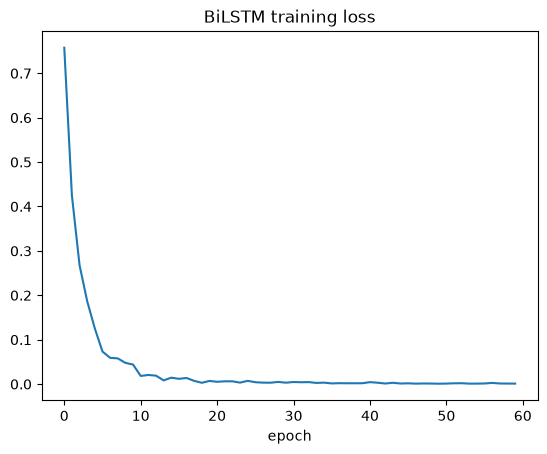

Saved: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\activity_bilstm.keras


In [8]:
model, history = train_model(build_bilstm, X, y, epochs=60)
print("final training accuracy:", round(history.history["accuracy"][-1], 3))

plt.plot(history.history["loss"])
plt.title("BiLSTM training loss"); plt.xlabel("epoch"); plt.show()

model.save(ACTIVITY_BILSTM_PATH)
print("Saved:", ACTIVITY_BILSTM_PATH)

## 5. Test with the project's inference code

In [9]:
labels_df = pd.read_csv(ACTIVITY_LABELS_CSV)
for _, row in labels_df.iterrows():
    result = predict_video(ACTIVITY_DIR / row["video_path"], model_type="bilstm")
    print(f"true={row['label']:9s} predicted={result['label']:9s} confidence={result['confidence']:.2f}")

true=Walking   predicted=Walking   confidence=1.00
true=Walking   predicted=Walking   confidence=1.00
true=Sitting   predicted=Sitting   confidence=1.00
true=Standing  predicted=Standing  confidence=1.00


**Done:** `models/activity_bilstm.keras` is saved. Next: notebook 06 (NLP + BERT).